In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

file_path = "/home/vidisha/Desktop/SentinelIDS/models/Monday-WorkingHours.pcap_ISCX.csv"

df = pd.read_csv(
    file_path,
    encoding="utf-8",
    encoding_errors="ignore"
)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (529918, 79)


In [2]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

df.columns = df.columns.str.strip()

print(df.columns.tolist())

['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE Flag Count

In [3]:
print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
print(df.info())

print("\nShape:")
print(df.shape)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())


First 5 rows:


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,49188,4,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,49188,1,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,49188,1,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,49188,1,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,49486,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 529918 entries, 0 to 529917
Data columns (total 79 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Destination Port             529918 non-null  int64  
 1   Flow Duration                529918 non-null  int64  
 2   Total Fwd Packets            529918 non-null  int64  
 3   Total Backward Packets       529918 non-null  int64  
 4   Total Length of Fwd Packets  529918 non-null  int64  
 5   Total Length of Bwd Packets  529918 non-null  int64  
 6   Fwd Packet Length Max        529918 non-null  int64  
 7   Fwd Packet Length Min        529918 non-null  int64  
 8   Fwd Packet Length Mean       529918 non-null  float64
 9   Fwd Packet Length Std        529918 non-null  float64
 10  Bwd Packet Length Max        529918 non-null  int64  
 11  Bwd Packet Length Min        529918 non-null  int64  
 12  Bwd Packet Length Mean       529918 non-null  f

Label
BENIGN    529918
Name: count, dtype: int64


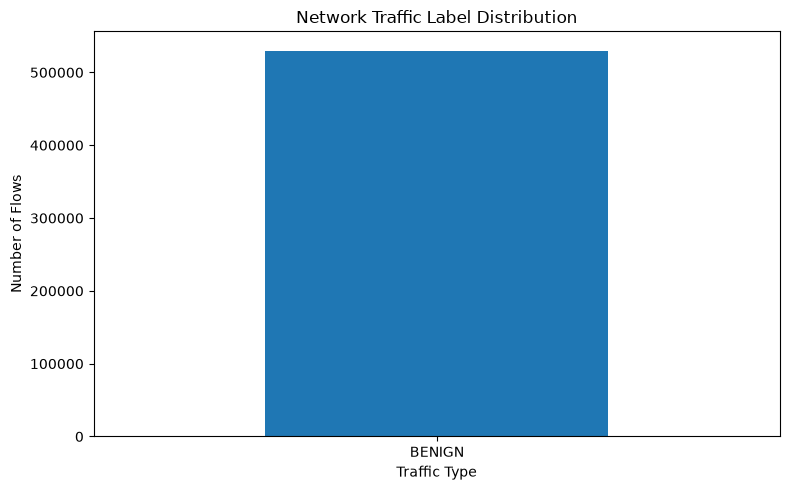

In [4]:
label_counts = df["Label"].value_counts()

print(label_counts)

plt.figure(figsize=(8, 5))
label_counts.plot(kind="bar")

plt.title("Network Traffic Label Distribution")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Flows")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [5]:
print("Missing values:")
missing = df.isnull().sum()
missing = missing[missing > 0]

print(missing)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nInfinite values:")
numeric_temp = df.select_dtypes(include=np.number)

inf_count = np.isinf(numeric_temp).sum().sum()

print(inf_count)

Missing values:
Flow Bytes/s    64
dtype: int64

Duplicate rows: 26935

Infinite values:
810


In [6]:
before = len(df)

df = df.drop_duplicates().reset_index(drop=True)

after = len(df)

print("Rows before:", before)
print("Rows after:", after)
print("Duplicates removed:", before - after)

Rows before: 529918
Rows after: 502983
Duplicates removed: 26935


In [7]:
target = "Label"

X = df.drop(columns=[target]).copy()

print("Number of features:", X.shape[1])

Number of features: 78


In [8]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

X = X[numeric_features].copy()

print("Numeric features:", len(numeric_features))
print(numeric_features)

Numeric features: 78
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Co

In [9]:
X = X.replace([np.inf, -np.inf], np.nan)

print("Missing values after infinity replacement:")
print(X.isnull().sum().sum())

Missing values after infinity replacement:
666


In [10]:
X = X.fillna(X.median(numeric_only=True))

print("Remaining missing values:")
print(X.isnull().sum().sum())

Remaining missing values:
0


In [11]:
constant_features = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

print("Constant features:", len(constant_features))

if constant_features:
    print(constant_features)

X = X.drop(columns=constant_features)

print("Features remaining:", X.shape[1])

Constant features: 10
['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Features remaining: 68


In [12]:
descriptive_stats = X.describe().T

descriptive_stats["missing"] = X.isnull().sum()

display(descriptive_stats)

,count,mean,std,min,25%,50%,75%,max,missing
Destination Port,502983.0,1.119055e+04,2.180535e+04,0.0,53.0,80.0,443.0,6.553500e+04,0
Flow Duration,502983.0,1.091931e+07,2.939182e+07,-1.0,195.0,36763.0,483715.5,1.200000e+08,0
Total Fwd Packets,502983.0,1.082891e+01,9.159937e+02,1.0,2.0,2.0,5.0,2.197590e+05,0
Total Backward Packets,502983.0,1.208024e+01,1.204322e+03,0.0,1.0,2.0,4.0,2.919220e+05,0
Total Length of Fwd Packets,502983.0,5.571517e+02,6.392081e+03,0.0,24.0,68.0,332.0,1.323378e+06,0
...,...,...,...,...,...,...,...,...,...
Active Min,502983.0,4.614940e+04,5.124585e+05,0.0,0.0,0.0,0.0,1.016597e+08,0
Idle Mean,502983.0,3.648521e+06,1.328598e+07,0.0,0.0,0.0,0.0,1.199997e+08,0
Idle Std,502983.0,2.132816e+05,2.226978e+06,0.0,0.0,0.0,0.0,7.514502e+07,0
Idle Max,502983.0,3.813654e+06,1.373204e+07,0.0,0.0,0.0,0.0,1.199997e+08,0


In [13]:
important_features = [
    "Destination Port",
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets",
    "Flow Bytes/s",
    "Flow Packets/s",
    "SYN Flag Count",
    "RST Flag Count",
    "ACK Flag Count"
]

available_features = [
    col for col in important_features
    if col in X.columns
]

display(X[available_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
Destination Port,502983.0,1.119055e+04,2.180535e+04,0.0,53.000000,80.000000,443.000000,6.553500e+04
Flow Duration,502983.0,1.091931e+07,2.939182e+07,-1.0,195.000000,36763.000000,483715.500000,1.200000e+08
Total Fwd Packets,502983.0,1.082891e+01,9.159937e+02,1.0,2.000000,2.000000,5.000000,2.197590e+05
Total Backward Packets,502983.0,1.208024e+01,1.204322e+03,0.0,1.000000,2.000000,4.000000,2.919220e+05
Total Length of Fwd Packets,502983.0,5.571517e+02,6.392081e+03,0.0,24.000000,68.000000,332.000000,1.323378e+06
Total Length of Bwd Packets,502983.0,1.885209e+04,2.746169e+06,0.0,6.000000,154.000000,428.000000,6.554530e+08
Flow Bytes/s,502983.0,1.497404e+06,2.512803e+07,-12000000.0,142.607429,4976.916276,136363.636364,2.071000e+09
Flow Packets/s,502983.0,5.680773e+04,2.168931e+05,-2000000.0,15.504777,88.911940,19230.769231,3.000000e+06
SYN Flag Count,502983.0,6.528054e-02,2.470205e-01,0.0,0.000000,0.000000,0.000000,1.000000e+00
RST Flag Count,502983.0,1.431460e-04,1.196352e-02,0.0,0.000000,0.000000,0.000000,1.000000e+00


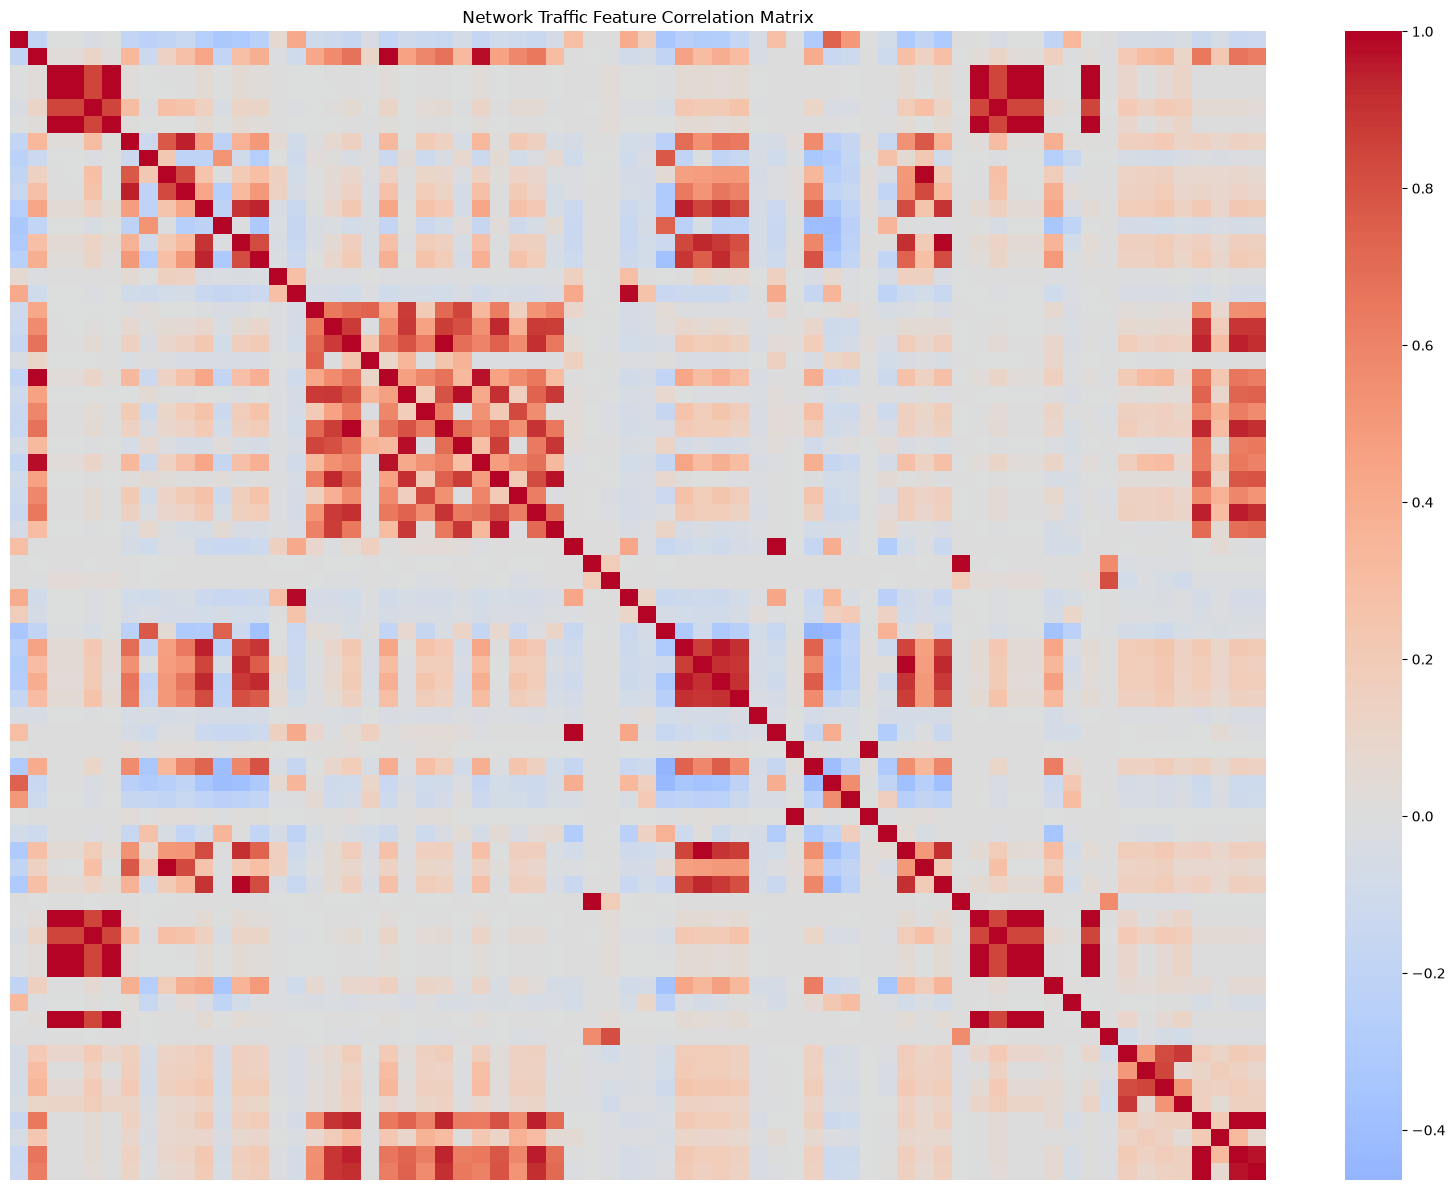

In [14]:
corr_matrix = X.corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    xticklabels=False,
    yticklabels=False
)

plt.title("Network Traffic Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [15]:
# CORRELATION — HIGHLY CORRELATED FEATURE PAIRS

# Keep numerical columns only
corr_features = df.select_dtypes(include=np.number)

# Replace infinity values
corr_features = corr_features.replace(
    [np.inf, -np.inf],
    np.nan
)

# Fill missing values
corr_features = corr_features.fillna(
    corr_features.median()
)

# Remove constant columns
corr_features = corr_features.loc[
    :,
    corr_features.nunique() > 1
]

# Create correlation matrix
corr_matrix = corr_features.corr()

# Absolute correlation
corr_abs = corr_matrix.abs()

# Upper triangle
upper = corr_abs.where(
    np.triu(
        np.ones(corr_abs.shape),
        k=1
    ).astype(bool)
)

# Find highly correlated pairs
high_corr_pairs = []

for column in upper.columns:
    for row in upper.index:

        value = upper.loc[row, column]

        if pd.notna(value) and value >= 0.95:
            high_corr_pairs.append(
                (row, column, value)
            )

# Sort by correlation
high_corr_pairs = sorted(
    high_corr_pairs,
    key=lambda x: x[2],
    reverse=True
)

print(
    "Highly correlated feature pairs:",
    len(high_corr_pairs)
)

for pair in high_corr_pairs[:20]:
    print(
        f"{pair[0]} <-> {pair[1]} : {pair[2]:.4f}"
    )

Highly correlated feature pairs: 40
Fwd PSH Flags <-> SYN Flag Count : 1.0000
Fwd Packet Length Mean <-> Avg Fwd Segment Size : 1.0000
Fwd Header Length <-> Fwd Header Length.1 : 1.0000
Total Fwd Packets <-> Subflow Fwd Packets : 1.0000
Total Length of Fwd Packets <-> Subflow Fwd Bytes : 1.0000
Total Backward Packets <-> Subflow Bwd Packets : 1.0000
Total Length of Bwd Packets <-> Subflow Bwd Bytes : 1.0000
Bwd Packet Length Mean <-> Avg Bwd Segment Size : 1.0000
Total Fwd Packets <-> act_data_pkt_fwd : 0.9995
Subflow Fwd Packets <-> act_data_pkt_fwd : 0.9995
Total Backward Packets <-> act_data_pkt_fwd : 0.9995
Subflow Bwd Packets <-> act_data_pkt_fwd : 0.9995
Total Fwd Packets <-> Total Backward Packets : 0.9993
Total Fwd Packets <-> Subflow Bwd Packets : 0.9993
Subflow Fwd Packets <-> Subflow Bwd Packets : 0.9993
Total Backward Packets <-> Subflow Fwd Packets : 0.9993
Total Length of Bwd Packets <-> Subflow Fwd Packets : 0.9990
Total Fwd Packets <-> Total Length of Bwd Packets : 0.99

In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (502983, 68)


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test = train_test_split(
    X_scaled,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)

Training samples: (402386, 68)
Testing samples: (100597, 68)


In [18]:
from sklearn.ensemble import IsolationForest

iso_model = IsolationForest(
    n_estimators=200,
    contamination=0.01,
    random_state=42,
    n_jobs=-1
)

iso_model.fit(X_train)

print("Isolation Forest training completed.")

Isolation Forest training completed.


In [19]:
predictions = iso_model.predict(X_test)

print("Prediction values:")
print(np.unique(predictions, return_counts=True))

Prediction values:
(array([-1,  1]), array([  981, 99616]))


In [20]:
prediction_labels = np.where(
    predictions == 1,
    "NORMAL",
    "ANOMALY"
)

print(pd.Series(prediction_labels).value_counts())

NORMAL     99616
ANOMALY      981
Name: count, dtype: int64


In [21]:
anomaly_scores = iso_model.decision_function(X_test)

print("Minimum anomaly score:", anomaly_scores.min())
print("Maximum anomaly score:", anomaly_scores.max())
print("Mean anomaly score:", anomaly_scores.mean())

Minimum anomaly score: -0.1446352120008223
Maximum anomaly score: 0.31256394191168835
Mean anomaly score: 0.2540115059970879


In [22]:
ids_results = pd.DataFrame({
    "Anomaly_Score": anomaly_scores,
    "Prediction": prediction_labels
})

ids_results.head()

,Anomaly_Score,Prediction
0,0.248775,NORMAL
1,0.278786,NORMAL
2,0.173182,NORMAL
3,0.282166,NORMAL
4,-0.007670,ANOMALY


In [23]:
score = ids_results["Anomaly_Score"]

ids_results["Risk_Level"] = pd.cut(
    score,
    bins=[-np.inf, score.quantile(0.01), score.quantile(0.05), np.inf],
    labels=["HIGH", "MEDIUM", "LOW"]
)

print(ids_results["Risk_Level"].value_counts())

Risk_Level
LOW       95567
MEDIUM     4024
HIGH       1006
Name: count, dtype: int64


In [24]:
anomalies = ids_results[
    ids_results["Prediction"] == "ANOMALY"
].copy()

print("Total test flows:", len(ids_results))
print("Detected anomalies:", len(anomalies))

print(
    "Anomaly percentage:",
    len(anomalies) / len(ids_results) * 100
)

Total test flows: 100597
Detected anomalies: 981
Anomaly percentage: 0.9751781862282175


In [25]:
top_anomalies = ids_results.sort_values(
    "Anomaly_Score",
    ascending=True
).head(20)

display(top_anomalies)

,Anomaly_Score,Prediction,Risk_Level
76914,-0.144635,ANOMALY,HIGH
26618,-0.142268,ANOMALY,HIGH
98425,-0.135114,ANOMALY,HIGH
51727,-0.132405,ANOMALY,HIGH
96955,-0.131930,ANOMALY,HIGH
18665,-0.130291,ANOMALY,HIGH
63675,-0.129183,ANOMALY,HIGH
39585,-0.126017,ANOMALY,HIGH
44164,-0.124781,ANOMALY,HIGH
31743,-0.122973,ANOMALY,HIGH


In [26]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest

X = df.drop(columns=["Label"], errors="ignore")

X = X.select_dtypes(include=np.number)

X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

X = X.fillna(X.median())

# Remove constant columns
X = X.loc[:, X.nunique() > 1]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

train_idx, test_idx = train_test_split(
    np.arange(len(X)),
    test_size=0.20,
    random_state=42
)

X_train = X_scaled[train_idx]

X_test = X_scaled[test_idx]

iso_model = IsolationForest(
    n_estimators=200,
    contamination=0.01,
    random_state=42,
    n_jobs=-1
)

iso_model.fit(X_train)

predictions = iso_model.predict(X_test)

anomaly_scores = iso_model.decision_function(X_test)

test_results = df.iloc[test_idx].copy()

test_results["Anomaly_Score"] = anomaly_scores

test_results["Prediction"] = np.where(
    predictions == 1,
    "NORMAL",
    "ANOMALY"
)

print("Test samples:", len(test_results))

print(
    "\nPrediction Distribution:"
)

print(
    test_results["Prediction"].value_counts()
)

print("\nTop 20 Most Suspicious Test Flows:")

display(
    test_results[
        test_results["Prediction"] == "ANOMALY"
    ]
    .sort_values(
        "Anomaly_Score",
        ascending=True
    )
    .head(20)
)

Test samples: 100597

Prediction Distribution:
Prediction
NORMAL     99616
ANOMALY      981
Name: count, dtype: int64

Top 20 Most Suspicious Test Flows:


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Anomaly_Score,Prediction
40920,80,119791969,172,304,263682,306070,8395,6,1533.034884,2053.546861,...,1.634494e+06,6997103,1701562,5.385136e+06,2.040080e+05,5845759,5151277,BENIGN,-0.144635,ANOMALY
33572,80,115583816,158,284,242339,288391,5840,6,1533.791139,2052.730110,...,1.970515e+06,7114521,1676836,5.859422e+06,9.040504e+05,7855695,5132365,BENIGN,-0.142268,ANOMALY
324518,443,65255641,2459,5633,74682,10587119,5545,0,30.370882,160.695642,...,0.000000e+00,7168031,7168031,5.803550e+07,0.000000e+00,58035499,58035499,BENIGN,-0.135114,ANOMALY
31114,80,115530778,122,209,187943,215568,5840,6,1540.516393,2025.786607,...,1.575980e+06,6044985,37701,6.403023e+06,9.346316e+05,8173892,5286302,BENIGN,-0.132405,ANOMALY
44111,443,104533518,289,641,37742,1038727,1077,0,130.595156,292.707320,...,0.000000e+00,17752630,17752630,8.678082e+07,0.000000e+00,86780823,86780823,BENIGN,-0.131930,ANOMALY
50841,443,85982882,314,582,37129,1020094,1061,0,118.245223,292.733401,...,0.000000e+00,11095919,11095919,7.488691e+07,0.000000e+00,74886914,74886914,BENIGN,-0.130291,ANOMALY
312392,443,65281703,18187,22827,101518,62558387,317,0,5.581899,3.943617,...,0.000000e+00,5990615,5990615,5.906037e+07,0.000000e+00,59060372,59060372,BENIGN,-0.129183,ANOMALY
265647,443,113385662,628,764,30785,1083223,6737,0,49.020701,409.913253,...,0.000000e+00,53965932,53965932,5.843834e+07,0.000000e+00,58438335,58438335,BENIGN,-0.126017,ANOMALY
436810,80,90781243,134,231,198294,234959,5840,6,1479.805970,1958.440493,...,1.268015e+06,6009705,1395757,5.354421e+06,3.944193e+05,6588899,5139433,BENIGN,-0.124781,ANOMALY
194687,443,63758976,2633,3533,21931,7206266,240,0,8.329282,18.531083,...,0.000000e+00,5431772,5431772,5.821939e+07,0.000000e+00,58219390,58219390,BENIGN,-0.122973,ANOMALY


Prediction Distribution:
Prediction
NORMAL     99616
ANOMALY      981
Name: count, dtype: int64


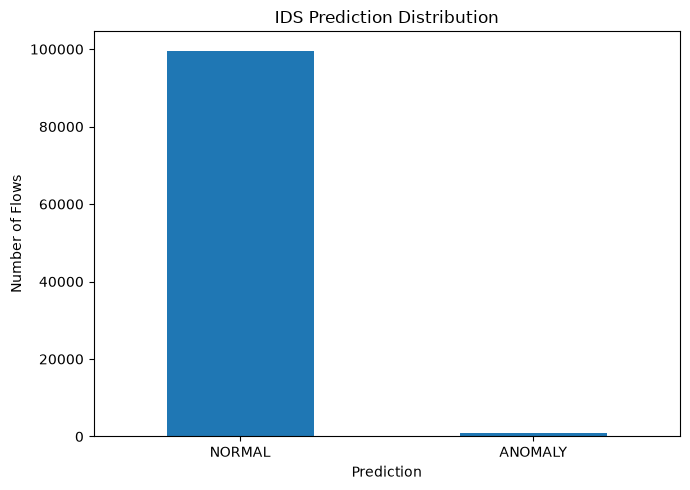

In [27]:
# IDS PREDICTION DISTRIBUTION

prediction_counts = ids_results["Prediction"].value_counts()

print("Prediction Distribution:")
print(prediction_counts)

plt.figure(figsize=(7, 5))

prediction_counts.plot(kind="bar")

plt.title("IDS Prediction Distribution")
plt.xlabel("Prediction")
plt.ylabel("Number of Flows")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [28]:
# PCA — 2 COMPONENTS

from sklearn.decomposition import PCA

# Prepare numerical features
pca_features = df.drop(
    columns=["Label"],
    errors="ignore"
)

pca_features = pca_features.select_dtypes(
    include=np.number
)

# Clean data
pca_features = pca_features.replace(
    [np.inf, -np.inf],
    np.nan
)

pca_features = pca_features.fillna(
    pca_features.median()
)

# Remove constant columns
pca_features = pca_features.loc[
    :,
    pca_features.nunique() > 1
]

# Standardize
pca_scaler = StandardScaler()

pca_scaled = pca_scaler.fit_transform(
    pca_features
)

# PCA
pca = PCA(n_components=2)

X_pca = pca.fit_transform(
    pca_scaled
)

print("PCA completed successfully.")

print(
    "Explained variance:",
    pca.explained_variance_ratio_
)

print(
    "Total explained variance:",
    round(
        pca.explained_variance_ratio_.sum() * 100,
        2
    ),
    "%"
)

PCA completed successfully.
Explained variance: [0.20546308 0.1417115 ]
Total explained variance: 34.72 %


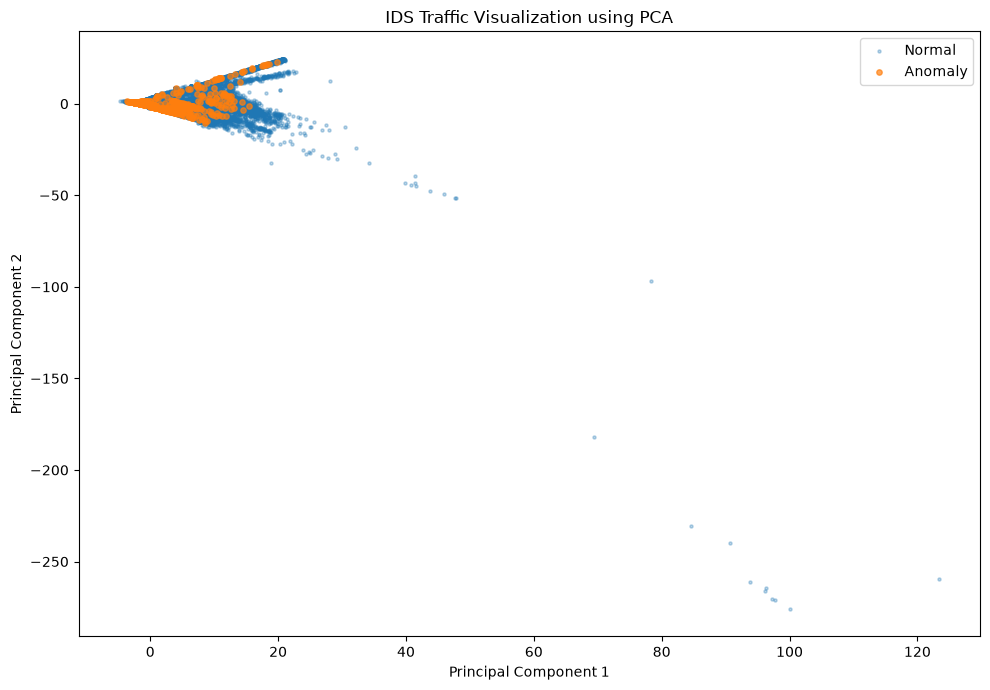

In [29]:
# PCA — NORMAL VS ANOMALY VISUALIZATION
X_pca = X_pca[ids_results.index]

# Create masks from existing IDS results
normal_mask = (
    ids_results["Prediction"] == "NORMAL"
).values

anomaly_mask = (
    ids_results["Prediction"] == "ANOMALY"
).values


# Create plot
plt.figure(figsize=(10, 7))

# Normal traffic
plt.scatter(
    X_pca[normal_mask, 0],
    X_pca[normal_mask, 1],
    s=5,
    alpha=0.3,
    label="Normal"
)

# Anomalous traffic
plt.scatter(
    X_pca[anomaly_mask, 0],
    X_pca[anomaly_mask, 1],
    s=15,
    alpha=0.7,
    label="Anomaly"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("IDS Traffic Visualization using PCA")

plt.legend()
plt.tight_layout()
plt.show()

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

file_path = "/home/vidisha/Desktop/SentinelIDS/models/Monday-WorkingHours.pcap_ISCX.csv"

df29 = pd.read_csv(
    file_path,
    encoding="utf-8",
    encoding_errors="ignore"
)

print("Dataset loaded successfully.")
print("Original shape:", df29.shape)

df29.columns = df29.columns.str.strip()

df29 = df29.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df29.shape)

target_column = "Label"

X29 = df29.drop(
    columns=[target_column],
    errors="ignore"
).copy()

X29 = X29.select_dtypes(
    include=np.number
).copy()

print("Number of numerical features:", X29.shape[1])

X29 = X29.replace(
    [np.inf, -np.inf],
    np.nan
)

X29 = X29.fillna(
    X29.median(numeric_only=True)
)

constant_columns = [
    column
    for column in X29.columns
    if X29[column].nunique(dropna=False) <= 1
]

if len(constant_columns) > 0:

    print(
        "Removing constant features:",
        constant_columns
    )

    X29 = X29.drop(
        columns=constant_columns
    )


print(
    "Features available for IDS:",
    X29.shape[1]
)

scaler29 = StandardScaler()

X29_scaled = scaler29.fit_transform(X29)

iso_model29 = IsolationForest(
    n_estimators=200,
    contamination=0.01,
    random_state=42,
    n_jobs=-1
)

iso_model29.fit(X29_scaled)

print("Isolation Forest trained successfully.")

sample_size = min(
    10000,
    len(X29_scaled)
)

rng = np.random.RandomState(42)

sample_indices = rng.choice(
    len(X29_scaled),
    size=sample_size,
    replace=False
)

X_sample29 = X29_scaled[
    sample_indices
]

sample_scores29 = iso_model29.decision_function(
    X_sample29
)

feature_results = []

for i, feature in enumerate(X29.columns):

    feature_values = X_sample29[:, i]

    if np.std(feature_values) == 0:

        correlation = 0

    else:

        correlation = np.corrcoef(
            feature_values,
            sample_scores29
        )[0, 1]

        if np.isnan(correlation):
            correlation = 0

    feature_results.append({
        "Feature": feature,
        "Correlation": correlation,
        "Absolute_Importance": abs(correlation)
    })

importance_df29 = pd.DataFrame(
    feature_results
)

importance_df29 = importance_df29.sort_values(
    by="Absolute_Importance",
    ascending=False
).reset_index(drop=True)

print("\nTop 20 features associated with IDS anomaly scores:")

display(
    importance_df29.head(20)
)

Dataset loaded successfully.
Original shape: (529918, 79)
Shape after removing duplicates: (502983, 79)
Number of numerical features: 78
Removing constant features: ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Features available for IDS: 68
Isolation Forest trained successfully.

Top 20 features associated with IDS anomaly scores:


,Feature,Correlation,Absolute_Importance
0,Flow Duration,-0.756734,0.756734
1,Fwd IAT Total,-0.746836,0.746836
2,Bwd IAT Total,-0.714713,0.714713
3,Flow IAT Max,-0.712841,0.712841
4,Fwd IAT Max,-0.702225,0.702225
5,Idle Max,-0.681833,0.681833
6,Idle Mean,-0.671745,0.671745
7,Bwd IAT Max,-0.666555,0.666555
8,Max Packet Length,-0.662270,0.662270
9,Idle Min,-0.648706,0.648706


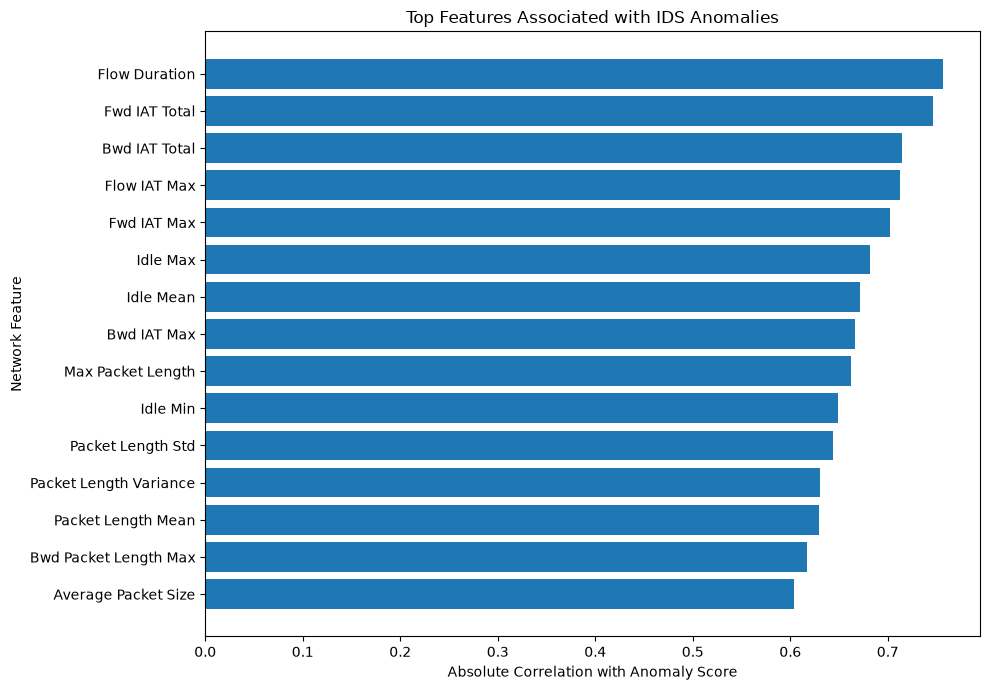

In [31]:
# VISUALIZE TOP IDS FEATURES

top_features29 = importance_df29.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features29["Feature"],
    top_features29["Absolute_Importance"]
)

plt.xlabel(
    "Absolute Correlation with Anomaly Score"
)

plt.ylabel(
    "Network Feature"
)

plt.title(
    "Top Features Associated with IDS Anomalies"
)

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()

In [32]:
# IDS PREDICTION

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

# Load dataset
file_path = "/home/vidisha/Desktop/SentinelIDS/models/Monday-WorkingHours.pcap_ISCX.csv"

df = pd.read_csv(
    file_path,
    encoding="utf-8",
    encoding_errors="ignore"
)

# Clean column names
df.columns = df.columns.str.strip()

# Remove duplicates
df = df.drop_duplicates().reset_index(drop=True)

# Separate features
X = df.drop(columns=["Label"], errors="ignore")

# Keep numerical columns only
X = X.select_dtypes(include=np.number)

# Replace infinity
X = X.replace([np.inf, -np.inf], np.nan)

# Fill missing values
X = X.fillna(X.median())

# Remove constant columns
X = X.loc[:, X.nunique() > 1]

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train Isolation Forest
model = IsolationForest(
    n_estimators=200,
    contamination=0.01,
    random_state=42,
    n_jobs=-1
)

model.fit(X_scaled)

# Generate predictions
predictions = model.predict(X_scaled)

# Generate anomaly scores
anomaly_scores = model.decision_function(X_scaled)

# Convert predictions
labels = np.where(
    predictions == 1,
    "NORMAL",
    "ANOMALY"
)

# Create results
ids_results = df.copy()

ids_results["Anomaly_Score"] = anomaly_scores
ids_results["Prediction"] = labels

# Display results
print("IDS prediction completed.")

print("\nPrediction distribution:")
print(ids_results["Prediction"].value_counts())

display(ids_results.head())

IDS prediction completed.

Prediction distribution:
Prediction
NORMAL     497953
ANOMALY      5030
Name: count, dtype: int64


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Anomaly_Score,Prediction
0,49188,4,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,0.256880,NORMAL
1,49188,1,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,0.229419,NORMAL
2,49486,3,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,0.252799,NORMAL
3,49486,1,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,0.228970,NORMAL
4,88,609,7,4,484,414,233,0,69.142857,111.967895,...,0.0,0,0,0.0,0.0,0,0,BENIGN,0.261989,NORMAL


In [33]:
# ANOMALY RATE

total_flows = len(ids_results)

normal_flows = (ids_results["Prediction"] == "NORMAL").sum()
anomaly_flows = (ids_results["Prediction"] == "ANOMALY").sum()

anomaly_rate = (anomaly_flows / total_flows) * 100

print("Total Flows   :", total_flows)
print("Normal Flows  :", normal_flows)
print("Anomaly Flows :", anomaly_flows)
print(f"Anomaly Rate  : {anomaly_rate:.2f}%")

Total Flows   : 502983
Normal Flows  : 497953
Anomaly Flows : 5030
Anomaly Rate  : 1.00%


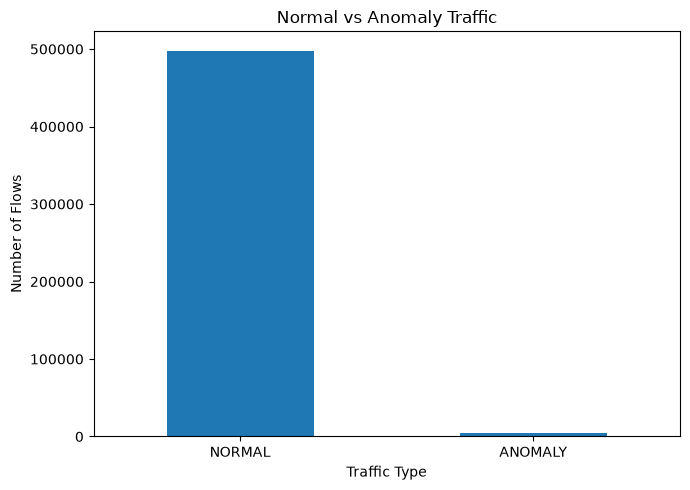

In [34]:
# NORMAL VS ANOMALY CHART

import matplotlib.pyplot as plt

prediction_counts = ids_results["Prediction"].value_counts()

plt.figure(figsize=(7, 5))
prediction_counts.plot(kind="bar")

plt.title("Normal vs Anomaly Traffic")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Flows")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

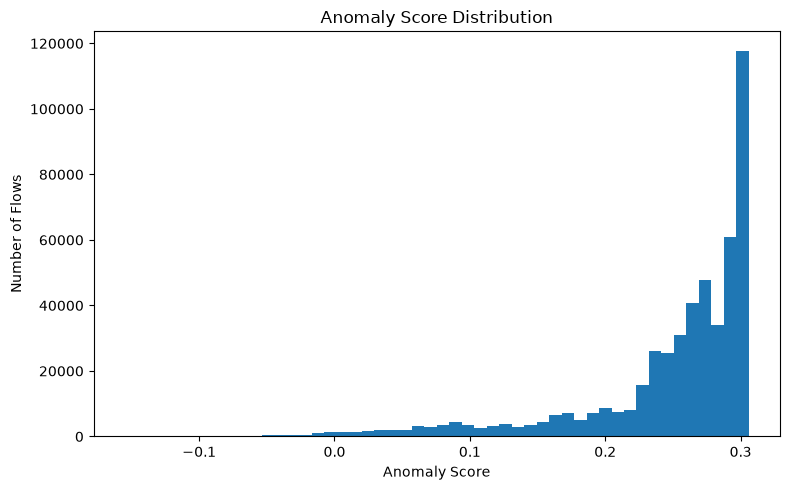

In [35]:
# ANOMALY SCORE DISTRIBUTION

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    ids_results["Anomaly_Score"],
    bins=50
)

plt.title("Anomaly Score Distribution")
plt.xlabel("Anomaly Score")
plt.ylabel("Number of Flows")

plt.tight_layout()
plt.show()

In [36]:
# MOST SUSPICIOUS FLOWS

suspicious_flows = ids_results.sort_values(
    by="Anomaly_Score",
    ascending=True
).head(20)

print("Top 20 Most Suspicious Flows:")
display(suspicious_flows)

Top 20 Most Suspicious Flows:


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Anomaly_Score,Prediction
36424,80,119490389,181,314,271217,326628,8760,6,1498.436464,2135.868117,...,2.452970e+06,9226634,1620772,5.317273e+06,2.768318e+05,6230357,5131212,BENIGN,-0.154907,ANOMALY
35177,80,119175540,167,303,257780,303331,5840,6,1543.592814,2040.395078,...,1.801456e+06,7127469,1663561,5.303167e+06,1.145499e+05,5520686,5142588,BENIGN,-0.148316,ANOMALY
40920,80,119791969,172,304,263682,306070,8395,6,1533.034884,2053.546861,...,1.634494e+06,6997103,1701562,5.385136e+06,2.040080e+05,5845759,5151277,BENIGN,-0.147527,ANOMALY
29010,80,116797388,191,299,281949,342687,6781,6,1476.172775,1977.833979,...,5.122710e+06,17452847,1068083,6.035097e+06,1.211231e+06,8359666,5101002,BENIGN,-0.146398,ANOMALY
327966,80,88602696,32613,43008,198422,96968228,1460,0,6.084138,11.734876,...,0.000000e+00,18908707,18908707,6.969399e+07,0.000000e+00,69693989,69693989,BENIGN,-0.145532,ANOMALY
33572,80,115583816,158,284,242339,288391,5840,6,1533.791139,2052.730110,...,1.970515e+06,7114521,1676836,5.859422e+06,9.040504e+05,7855695,5132365,BENIGN,-0.144564,ANOMALY
26307,80,119880597,265,451,435953,494505,14156,0,1645.105660,2377.682376,...,7.205544e+06,24806039,2622796,6.115903e+06,1.756243e+06,10066551,5008515,BENIGN,-0.141862,ANOMALY
7282,80,119999835,193200,256740,1162781,575681633,2920,0,6.018535,10.703418,...,0.000000e+00,101659665,101659665,6.488790e+06,0.000000e+00,6488790,6488790,BENIGN,-0.140803,ANOMALY
496901,80,111485719,115727,147504,677007,399414759,341,0,5.850035,2.293702,...,0.000000e+00,44416873,44416873,6.706885e+07,0.000000e+00,67068846,67068846,BENIGN,-0.137770,ANOMALY
38255,80,114942691,154,262,230331,270197,5840,6,1495.655844,2042.917606,...,2.913696e+05,2660697,1499627,5.675310e+06,8.464445e+05,8249956,5167316,BENIGN,-0.137083,ANOMALY


In [37]:
# RISK LEVEL

def assign_risk(row):
    if row["Prediction"] == "NORMAL":
        return "LOW"

    score = row["Anomaly_Score"]

    if score < -0.10:
        return "HIGH"
    elif score < 0:
        return "MEDIUM"
    else:
        return "LOW"

ids_results["Risk_Level"] = ids_results.apply(
    assign_risk,
    axis=1
)

print(ids_results["Risk_Level"].value_counts())

Risk_Level
LOW       497953
MEDIUM      4882
HIGH         148
Name: count, dtype: int64


Risk Distribution:
Risk_Level
LOW       497953
MEDIUM      4882
HIGH         148
Name: count, dtype: int64


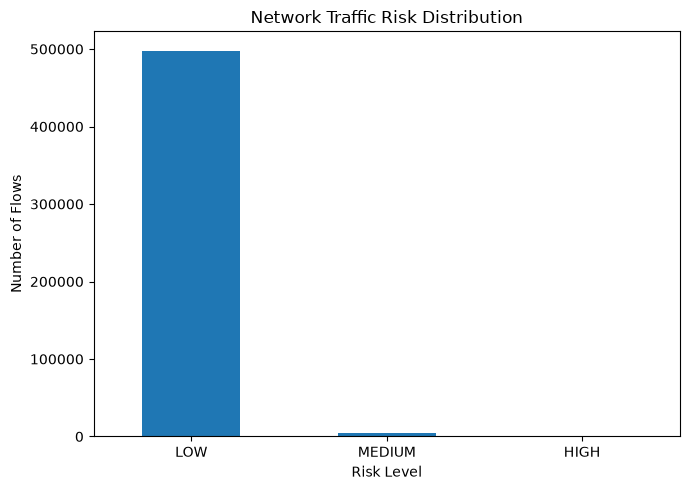

In [38]:
# RISK DISTRIBUTION

risk_counts = ids_results["Risk_Level"].value_counts()

print("Risk Distribution:")
print(risk_counts)

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

risk_counts.plot(kind="bar")

plt.title("Network Traffic Risk Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Number of Flows")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [39]:
# HIGH-RISK TRAFFIC

high_risk_traffic = ids_results[
    ids_results["Risk_Level"] == "HIGH"
].copy()

print("Number of High-Risk Flows:", len(high_risk_traffic))

display(high_risk_traffic.head(20))

Number of High-Risk Flows: 148


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Anomaly_Score,Prediction,Risk_Level
324,443,62101008,1011,1807,53666,3121853,1682,0,53.082097,270.087559,...,3214474,3214474,58808771.00,0.000000e+00,58808771,58808771,BENIGN,-0.109901,ANOMALY,HIGH
376,443,62645702,1167,1737,59484,3126766,1682,0,50.971722,249.395681,...,3855746,3855746,58514144.00,0.000000e+00,58514144,58514144,BENIGN,-0.116613,ANOMALY,HIGH
1500,443,119970563,1266,1828,62744,3149760,1678,0,49.560821,247.422108,...,3680465,90788,58081215.00,5.623762e+04,58120981,58041449,BENIGN,-0.118553,ANOMALY,HIGH
1633,443,64046294,764,1851,53404,3119575,1682,0,69.900524,306.867103,...,5288878,5288878,58679681.00,0.000000e+00,58679681,58679681,BENIGN,-0.121797,ANOMALY,HIGH
2045,443,100675781,110,83,117424,16519,5760,6,1067.490909,1180.505216,...,41802729,200355,13212802.75,8.531121e+06,24734131,5026974,BENIGN,-0.107029,ANOMALY,HIGH
2051,443,108406061,114,90,121984,16864,5760,6,1070.035088,1193.069485,...,40565152,327984,12413274.80,6.547020e+06,23491828,7862461,BENIGN,-0.107527,ANOMALY,HIGH
2424,443,51056532,668,910,7685,1957588,267,0,11.504491,26.396100,...,11217465,2756220,18541295.50,1.555750e+07,29542111,7540480,BENIGN,-0.116161,ANOMALY,HIGH
2723,443,108667569,227,297,10710,561870,772,0,47.180617,143.132614,...,18654132,23008,44983608.00,2.850913e+04,45003767,44963449,BENIGN,-0.100271,ANOMALY,HIGH
4538,443,62349750,671,814,7322,1665615,736,0,10.912072,37.784302,...,3677386,3677386,58597551.00,0.000000e+00,58597551,58597551,BENIGN,-0.102561,ANOMALY,HIGH
4684,80,119999876,219759,291922,1323378,655453030,367,0,6.021951,8.349883,...,0,0,0.00,0.000000e+00,0,0,BENIGN,-0.113532,ANOMALY,HIGH


In [40]:
# DESTINATION PORT ANALYSIS

possible_port_columns = [
    "Destination Port",
    " Destination Port",
    "Dst Port",
    " Destination Port "
]

port_column = None

for column in possible_port_columns:
    if column in ids_results.columns:
        port_column = column
        break

if port_column is not None:

    anomaly_ports = ids_results[
        ids_results["Prediction"] == "ANOMALY"
    ][port_column].value_counts().head(20)

    print("Top Destination Ports in Anomalous Traffic:")
    print(anomaly_ports)

else:
    print("Destination Port column was not found.")

Top Destination Ports in Anomalous Traffic:
Destination Port
443      3305
53        929
80        696
389        28
8081       23
445        14
3268       13
5353        6
137         1
50472       1
123         1
55031       1
57381       1
34675       1
34676       1
55862       1
43988       1
64610       1
39349       1
53926       1
Name: count, dtype: int64


In [41]:
#  PROTOCOL ANALYSIS

possible_protocol_columns = [
    "Protocol",
    " Protocol",
    "protocol"
]

protocol_column = None

for column in possible_protocol_columns:
    if column in ids_results.columns:
        protocol_column = column
        break

if protocol_column is not None:

    anomaly_protocols = ids_results[
        ids_results["Prediction"] == "ANOMALY"
    ][protocol_column].value_counts()

    print("Protocols in Anomalous Traffic:")
    print(anomaly_protocols)

else:
    print("Protocol column was not found.")

Protocol column was not found.


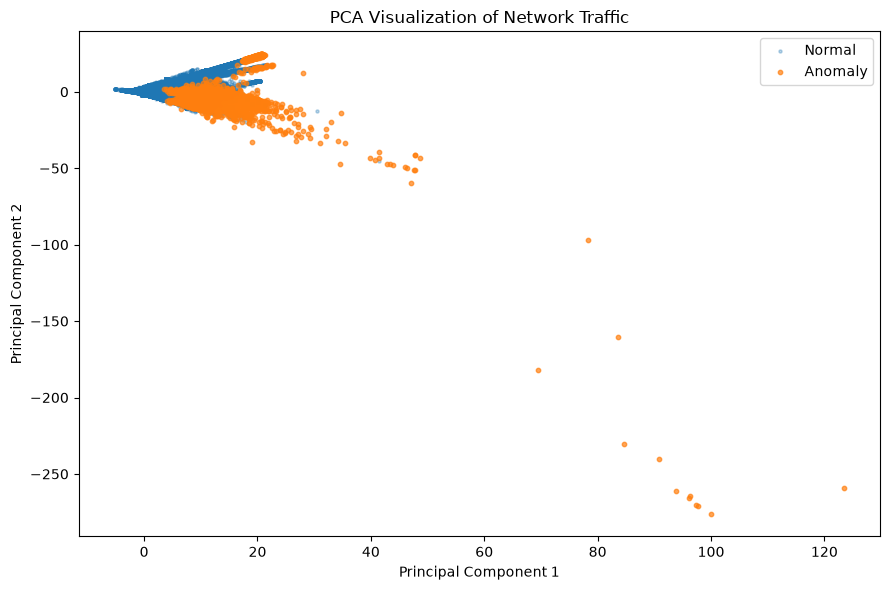

In [42]:
# PCA VISUALIZATION

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_scaled)

pca_results = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

pca_results["Prediction"] = ids_results["Prediction"].values

normal_data = pca_results[
    pca_results["Prediction"] == "NORMAL"
]

anomaly_data = pca_results[
    pca_results["Prediction"] == "ANOMALY"
]

plt.figure(figsize=(9, 6))

plt.scatter(
    normal_data["PC1"],
    normal_data["PC2"],
    s=5,
    alpha=0.3,
    label="Normal"
)

plt.scatter(
    anomaly_data["PC1"],
    anomaly_data["PC2"],
    s=10,
    alpha=0.7,
    label="Anomaly"
)

plt.title("PCA Visualization of Network Traffic")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()

plt.tight_layout()
plt.show()

In [43]:
# MODEL STABILITY ANALYSIS

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

file_path = "/home/vidisha/Desktop/SentinelIDS/models/Monday-WorkingHours.pcap_ISCX.csv"

stability_df = pd.read_csv(
    file_path,
    encoding="latin1"
)

# Clean column names
stability_df.columns = (
    stability_df.columns
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# Remove duplicates
stability_df = stability_df.drop_duplicates().reset_index(drop=True)

if "Label" in stability_df.columns:
    stability_X = stability_df.drop(columns=["Label"])
else:
    stability_X = stability_df.copy()

# Keep numerical columns
stability_X = stability_X.select_dtypes(include=[np.number])

# Replace infinity
stability_X = stability_X.replace(
    [np.inf, -np.inf],
    np.nan
)

# Convert to numeric
stability_X = stability_X.apply(
    pd.to_numeric,
    errors="coerce"
)

# Remove completely empty columns
stability_X = stability_X.dropna(
    axis=1,
    how="all"
)

# Fill missing values
stability_X = stability_X.fillna(
    stability_X.median()
)

# Remove constant columns
stability_X = stability_X.loc[
    :,
    stability_X.nunique() > 1
]

# Final safety cleanup
stability_X = stability_X.replace(
    [np.inf, -np.inf],
    np.nan
)

stability_X = stability_X.fillna(0)

stability_scaler = StandardScaler()

stability_X_scaled = stability_scaler.fit_transform(
    stability_X
)

random_states = [1, 10, 42, 100, 200]

stability_results = []

for seed in random_states:

    stability_model = IsolationForest(
        n_estimators=100,
        contamination=0.01,
        random_state=seed,
        n_jobs=-1
    )

    stability_model.fit(stability_X_scaled)

    stability_predictions = stability_model.predict(
        stability_X_scaled
    )

    anomaly_count = np.sum(
        stability_predictions == -1
    )

    total_count = len(stability_predictions)

    anomaly_rate = (
        anomaly_count / total_count
    ) * 100

    stability_results.append({
        "Random_State": seed,
        "Total_Flows": total_count,
        "Anomaly_Count": anomaly_count,
        "Anomaly_Rate_%": round(anomaly_rate, 2)
    })

stability_table = pd.DataFrame(
    stability_results
)

print("=" * 60)
print("MODEL STABILITY ANALYSIS")
print("=" * 60)

display(stability_table)

MODEL STABILITY ANALYSIS


,Random_State,Total_Flows,Anomaly_Count,Anomaly_Rate_%
0,1,502983,5029,1.0
1,10,502983,5030,1.0
2,42,502983,5030,1.0
3,100,502983,5030,1.0
4,200,502983,5030,1.0


In [44]:
# TEST ONE NETWORK FLOW

sample_flow = X.iloc[[0]]

sample_flow_scaled = scaler.transform(sample_flow)

sample_prediction = model.predict(sample_flow_scaled)[0]
sample_score = model.decision_function(sample_flow_scaled)[0]

if sample_prediction == 1:
    sample_label = "NORMAL"
else:
    sample_label = "ANOMALY"

print("Prediction    :", sample_label)
print("Anomaly Score :", sample_score)

Prediction    : NORMAL
Anomaly Score : 0.2568804145706097


In [45]:
# REUSABLE PREDICTION FUNCTION

def predict_network_flow(row_number):

    if row_number < 0 or row_number >= len(X):
        print("Invalid row number.")
        return

    flow = X.iloc[[row_number]]

    flow_scaled = scaler.transform(flow)

    prediction = model.predict(flow_scaled)[0]
    score = model.decision_function(flow_scaled)[0]

    if prediction == 1:
        label = "NORMAL"
    else:
        label = "ANOMALY"

    print("Row Number    :", row_number)
    print("Prediction    :", label)
    print("Anomaly Score :", score)


# Example
predict_network_flow(0)

Row Number    : 0
Prediction    : NORMAL
Anomaly Score : 0.2568804145706097


In [46]:
# EXPORT COMPLETE RESULTS

output_file = "/home/vidisha/Desktop/SentinelIDS/models/IDS_Complete_Results.csv"

ids_results.to_csv(
    output_file,
    index=False
)

print("IDS results exported successfully.")
print("File:", output_file)

IDS results exported successfully.
File: /home/vidisha/Desktop/SentinelIDS/models/IDS_Complete_Results.csv


In [47]:
# EXPORT SUSPICIOUS TRAFFIC

suspicious_file = "/home/vidisha/Desktop/SentinelIDS/models/IDS_Suspicious_Traffic.csv"

suspicious_traffic = ids_results[
    ids_results["Prediction"] == "ANOMALY"
].copy()

suspicious_traffic.to_csv(
    suspicious_file,
    index=False
)

print("Suspicious traffic exported successfully.")
print("File:", suspicious_file)
print("Suspicious flows:", len(suspicious_traffic))

Suspicious traffic exported successfully.
File: /home/vidisha/Desktop/SentinelIDS/models/IDS_Suspicious_Traffic.csv
Suspicious flows: 5030


In [48]:
# FEATURE VARIABILITY ANALYSIS

feature_variance = X.var().sort_values(
    ascending=False
)

feature_analysis = pd.DataFrame({
    "Feature": feature_variance.index,
    "Variance": feature_variance.values
})

print("Top 20 Most Variable Features:")

display(
    feature_analysis.head(20)
)

Top 20 Most Variable Features:


,Feature,Variance
0,Flow Duration,8.638790e+14
1,Fwd IAT Total,8.539112e+14
2,Bwd IAT Total,8.029831e+14
3,Flow Bytes/s,6.314177e+14
4,Flow IAT Max,2.049418e+14
5,Fwd IAT Max,2.033659e+14
6,Idle Max,1.885689e+14
7,Idle Mean,1.765171e+14
8,Bwd IAT Max,1.747375e+14
9,Idle Min,1.701330e+14


In [49]:
# MODULE 48 — FINAL IDS SUMMARY

total_flows = len(ids_results)

normal_flows = (
    ids_results["Prediction"] == "NORMAL"
).sum()

anomaly_flows = (
    ids_results["Prediction"] == "ANOMALY"
).sum()

high_risk_flows = (
    ids_results["Risk_Level"] == "HIGH"
).sum()

anomaly_rate = (
    anomaly_flows / total_flows
) * 100

print("=" * 50)
print("             IDS FINAL SUMMARY")
print("=" * 50)

print(f"Total Network Flows     : {total_flows}")
print(f"Normal Flows            : {normal_flows}")
print(f"Anomalous Flows         : {anomaly_flows}")
print(f"Anomaly Rate            : {anomaly_rate:.2f}%")
print(f"High-Risk Flows         : {high_risk_flows}")

print("=" * 50)
print("Model: Isolation Forest")
print("Detection Type: Unsupervised Anomaly Detection")
print("=" * 50)

             IDS FINAL SUMMARY
Total Network Flows     : 502983
Normal Flows            : 497953
Anomalous Flows         : 5030
Anomaly Rate            : 1.00%
High-Risk Flows         : 148
Model: Isolation Forest
Detection Type: Unsupervised Anomaly Detection


In [50]:
                    CICIDS2017
                         │
                         ▼
                Data Collection
                         │
                         ▼
                Data Cleaning
          ┌──────────────┴──────────────┐
          │                             │
     Missing Values                Duplicates
          │                             │
          └──────────────┬──────────────┘
                         ▼
                 Feature Selection
                         │
                         ▼
                 Feature Scaling
                         │
                         ▼
                Isolation Forest
                         │
                         ▼
                 Anomaly Score
                         │
             ┌───────────┴───────────┐
             ▼                       ▼
          NORMAL                  ANOMALY
                                     │
                                     ▼
                               Risk Analysis
                                     │
                                     ▼
                               Power BI Report

IndentationError: unindent does not match any outer indentation level (<string>, line 4)

In [53]:
import json
import joblib

# Save trained model
joblib.dump(model, "model.joblib")

# Save scaler
joblib.dump(scaler, "scaler.joblib")

# Save feature order used during training
with open("feature_columns.json", "w") as f:
    json.dump(list(X.columns), f, indent=4)

print("Export completed successfully!")

import os
print(os.listdir("."))

Export completed successfully!
['ids_detection.ipynb', 'scaler.joblib', '.ipynb_checkpoints', 'IDS_Suspicious_Traffic.csv', 'model.joblib', 'feature_columns.json', 'IDS_Complete_Results.csv', 'Monday-WorkingHours.pcap_ISCX.csv']


In [57]:
print(df["Label"].unique())
print(df["Label"].value_counts())
print(df["Label"])
print(y)

<StringArray>
['BENIGN']
Length: 1, dtype: str
Label
BENIGN    502983
Name: count, dtype: int64
0         BENIGN
1         BENIGN
2         BENIGN
3         BENIGN
4         BENIGN
           ...  
502978    BENIGN
502979    BENIGN
502980    BENIGN
502981    BENIGN
502982    BENIGN
Name: Label, Length: 502983, dtype: str


NameError: name 'y' is not defined